<a href="https://colab.research.google.com/github/YafetG3/L02-hedonic-pricing/blob/main/L02_hedonic_pricing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mofeoluwa Akande, Yafet Getachew, Grady Berlik, Eyram Golo

**Date:** 11/11/26

(16814, 19)
    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces        hvac_description  \
0                            0           0  Warm and Cool Air Zone   
1                            0           0            

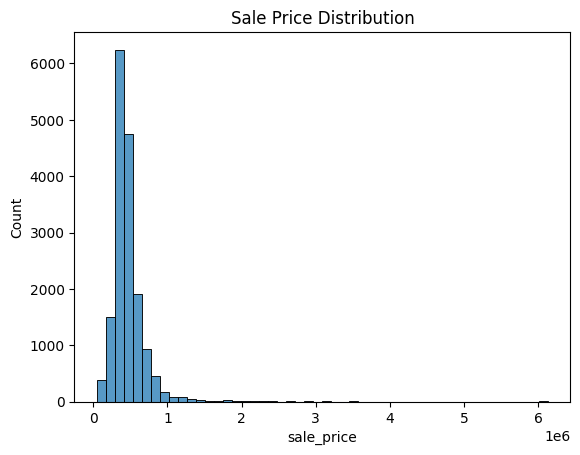

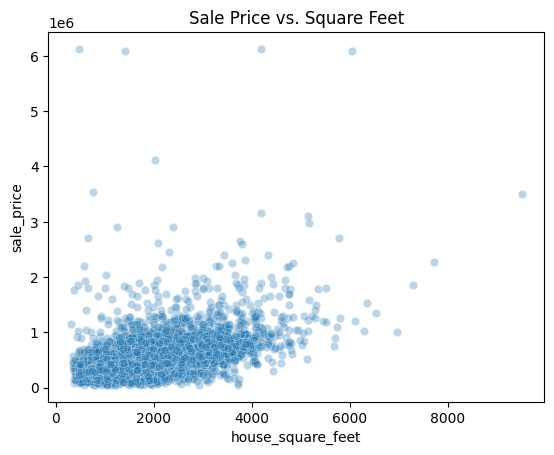

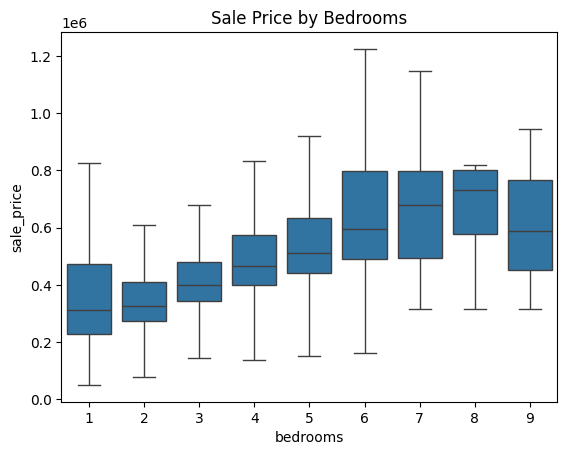

In [ ]:
#Part 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/EvilSauce/L02-hedonic-pricing/main/data/pierce_county_house_sales.csv"
df = pd.read_csv(url)
print(df.shape)
print(df.head())

df.info()
print(df.isna().sum())
print(df.describe())

# cleaning
df = df.drop_duplicates()
df["sale_date"] = pd.to_datetime(df["sale_date"])

# blank = no waterfront/view
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("No View")
df = df.dropna()

# drop weird values
df = df[(df["sale_price"] >= 50000) &
        (df["house_square_feet"] >= 300) &
        (df["bedrooms"].between(1, 10)) &
        (df["bathrooms"] >= 1)]
print("Cleaned shape:", df.shape)

# plots
sns.histplot(df["sale_price"], bins=50)
plt.title("Sale Price Distribution")
plt.show()

sns.scatterplot(data=df, x="house_square_feet", y="sale_price", alpha=0.3)
plt.title("Sale Price vs. Square Feet")
plt.show()

sns.boxplot(data=df, x="bedrooms", y="sale_price", showfliers=False)
plt.title("Sale Price by Bedrooms")
plt.show()

In [ ]:
#Part 2
# new features
df["age"] = 2020 - df["year_built"]
df["sale_month"] = df["sale_date"].dt.month
df = df.drop(columns=["sale_date", "year_built"])

# lump rare categories into "Other" so we don't get tiny dummy columns and drop dummy traps
cat_cols = df.select_dtypes(include=["object", "string"]).columns
for col in cat_cols:
    counts = df[col].value_counts()
    df[col] = df[col].replace(counts[counts < 50].index, "Other")

df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print(df.shape)
print(df.head())

(16663, 41)
   sale_price  house_square_feet  attic_finished_square_feet  \
0      380000               2157                           0   
1      383000               2238                           0   
2      419900               1452                           0   
3      251660                832                           0   
4      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces  stories  bedrooms  bathrooms  ...  \
0                            0           0        2         3          3  ...   
1                            0           0        2         4          3  ...   
2                      

In [ ]:
#Part 3
from sklearn.model_selection import train_test_split

X = df.drop(columns=["sale_price"])
y = df["sale_price"]

# random_state keeps the split the same for everyone
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (13330, 40)
Test: (3333, 40)


In [ ]:
# Part 4

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

results = []
def record(name, p_tr, p_te, k):
    results.append(dict(model=name, n_features=k,
                        RMSE_train=rmse(y_train, p_tr), RMSE_test=rmse(y_test, p_te),
                        R2_train=r2_score(y_train, p_tr), R2_test=r2_score(y_test, p_te)))

m1 = ["house_square_feet"]
m2 = m1 + ["bedrooms", "bathrooms", "stories", "age"]
m3 = m2 + ["fireplaces", "attached_garage_square_feet", "detached_garage_square_feet",
           "attic_finished_square_feet", "basement_square_feet"]
m4 = list(X_train.columns)          # everything: numeric + all dummies + sale_month

specs = {"M1: sq ft only": m1,
         "M2: + beds, baths, stories, age": m2,
         "M3: + garages, attic, basement, fireplaces": m3,
         "M4: all features (incl. dummies, month)": m4}

for name, cols in specs.items():
    lr = LinearRegression().fit(X_train[cols], y_train)
    record(name, lr.predict(X_train[cols]), lr.predict(X_test[cols]), len(cols))

results_df = pd.DataFrame(results).set_index("model")
results_df.round(3)

,n_features,RMSE_train,RMSE_test,R2_train,R2_test
model,,,,,
M1: sq ft only,1,201651.086,166028.940,0.278,0.360
"M2: + beds, baths, stories, age",5,194263.204,158087.766,0.330,0.420
"M3: + garages, attic, basement, fireplaces",10,182909.414,144932.874,0.406,0.512
"M4: all features (incl. dummies, month)",40,160361.727,124831.866,0.543,0.638


##Which simple model does best?
M4 (all 40 features) is clearly best: test RMSE about \$124.8k and R² 0.638, versus \$166.0k and 0.360 for square footage alone. Each step adds information and test error falls every time (166.0k, 158.1k, 144.9k, 124.8k), so the smaller models are underfit.

Train and test metrics are close, so there is no sign of overfitting. Test RMSE is actually lower than train RMSE for every model. That comes from the random split putting a few more extreme sales in the training set (the cleaned data still contains about 58 houses priced above \$1,000 per sq ft, which look like multi-parcel sales); a different seed could flip it.

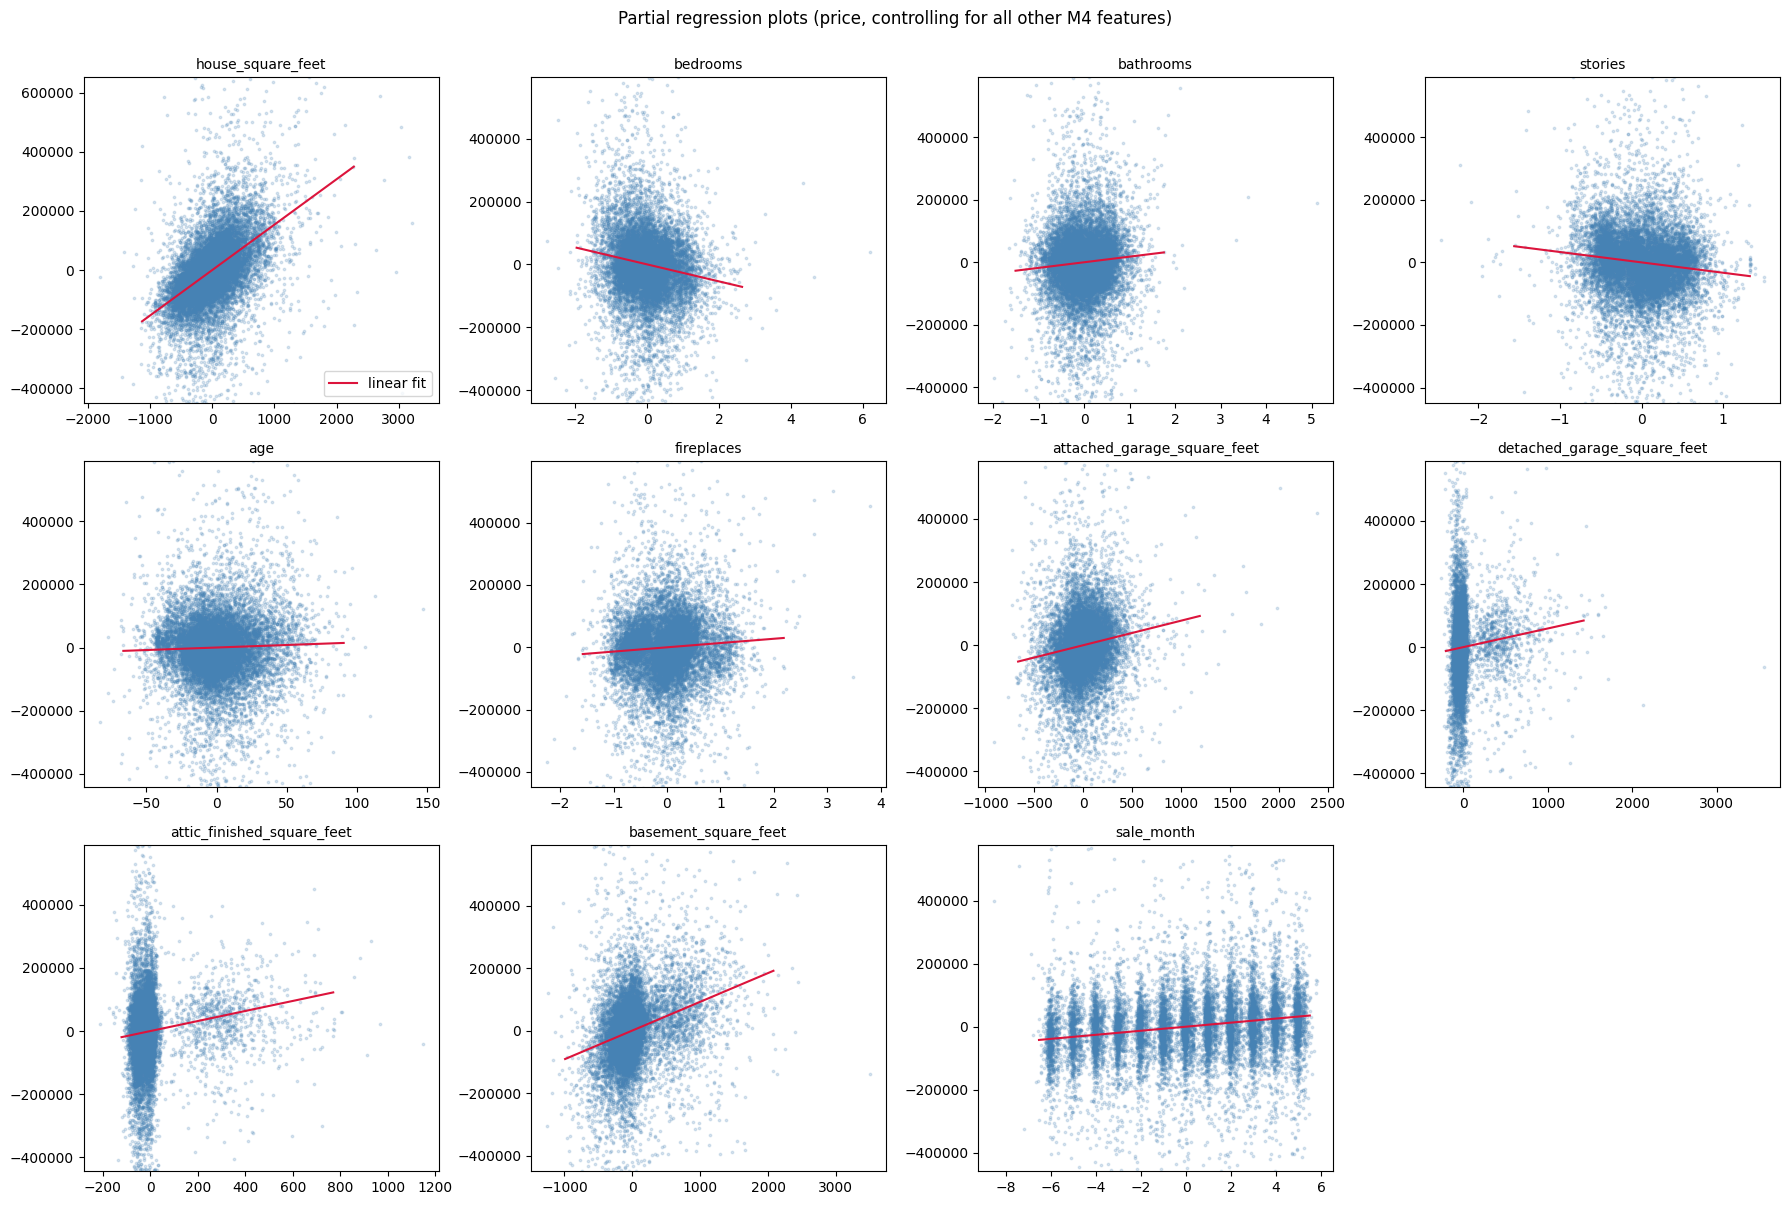

In [ ]:
# Part 5

import statsmodels.api as sm

Xc = X_train[m4].astype(float)
yt = y_train.astype(float)
plot_vars = ["house_square_feet", "bedrooms", "bathrooms", "stories", "age", "fireplaces",
             "attached_garage_square_feet", "detached_garage_square_feet",
             "attic_finished_square_feet", "basement_square_feet", "sale_month"]

def partial_plot(ax, var):
    # residualize price and the variable on all the OTHER features of M4
    others = [c for c in Xc.columns if c != var]
    Z = sm.add_constant(Xc[others])
    ry = sm.OLS(yt, Z).fit().resid
    rx = sm.OLS(Xc[var], Z).fit().resid
    ax.scatter(rx, ry, s=3, alpha=.2, color="steelblue")
    b = np.polyfit(rx, ry, 1)
    xs = np.linspace(rx.quantile(.001), rx.quantile(.999), 100)
    ax.plot(xs, np.polyval(b, xs), color="crimson", lw=1.5, label="linear fit")
    ax.set_ylim(ry.quantile(.005), ry.quantile(.995))
    ax.set_title(var, fontsize=10)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, v in zip(axes.ravel(), plot_vars):
    partial_plot(ax, v)
for ax in axes.ravel()[len(plot_vars):]:
    ax.axis("off")
axes[0, 0].legend()
fig.suptitle("Partial regression plots (price, controlling for all other M4 features)", y=1.0)
plt.tight_layout(); plt.show()

**Non-linearities.** Yes, several. In a partial regression plot a linear relationship shows up as a straight, evenly spread band along the red line, so look for curvature away from it:

- **House size** curves upward: the cloud bends above the line for the largest houses, so each extra square foot is worth more in big homes (price likely scales proportionally with size, which suggests a log form).
- **Age** is U-shaped: holding other features fixed, both the newest and the oldest homes sit above mid-age ones. A single straight line is nearly flat and misses this.
- **Bathrooms** and **fireplaces** bend upward at the high end (few observations there).
- **Basement** square footage flattens out for large basements (diminishing returns), and **detached garage** size rises and then levels off.
- **Bedrooms** and **stories** have *negative* slopes: for a given square footage, more bedrooms means smaller rooms and more stories is worth less than the same area on one floor.
- **Attached garage, finished attic and sale month** look close to linear. Attic and detached garage are zero for most houses (the vertical stripe at 0), so a "has one" indicator plus a size term is a better form.

In [ ]:
# Part 6

def build_features(Xd):
    F = pd.DataFrame(index=Xd.index)
    F["log_sqft"] = np.log(Xd["house_square_feet"])
    F["age"] = Xd["age"]
    F["age_sq"] = Xd["age"] ** 2 / 100
    F["new_build"] = (Xd["age"] <= 2).astype(int)
    F["bedrooms"] = Xd["bedrooms"]
    F["bathrooms"] = Xd["bathrooms"]
    F["stories"] = Xd["stories"]
    F["fireplaces"] = Xd["fireplaces"].clip(upper=3)
    F["sale_month"] = Xd["sale_month"]

    gar = Xd["attached_garage_square_feet"] + Xd["detached_garage_square_feet"]
    F["has_garage"] = (gar > 0).astype(int)
    F["log_garage"] = np.where(gar > 0, np.log(gar.clip(lower=1) / 400), 0.0)       #centered at 400 sq ft
    F["has_basement"] = (Xd["basement_square_feet"] > 0).astype(int)
    F["log_basement"] = np.where(Xd["basement_square_feet"] > 0,
                                 np.log(Xd["basement_square_feet"].clip(lower=1) / 500), 0.0)
    F["has_attic"] = (Xd["attic_finished_square_feet"] > 0).astype(int)

    wf = [c for c in Xd.columns if c.startswith("waterfront_type_")]
    vw = [c for c in Xd.columns if c.startswith("view_quality_")]
    F["waterfront"] = (Xd[wf].sum(axis=1) > 0).astype(int)
    F["has_view"] = (Xd[vw].sum(axis=1) > 0).astype(int)

    other = [c for c in Xd.columns if c.startswith(("hvac_description_", "exterior_", "roof_cover_",
                                                    "interior_", "utility_sewer_"))]
    F = pd.concat([F, Xd[other]], axis=1)

    # interactions
    F["logsqft_x_waterfront"] = F["log_sqft"] * F["waterfront"]
    F["logsqft_x_view"] = F["log_sqft"] * F["has_view"]
    F["logsqft_x_age"] = F["log_sqft"] * F["age"] / 10
    F["logsqft_x_bath"] = F["log_sqft"] * F["bathrooms"]
    F["bath_x_bed"] = F["bathrooms"] * F["bedrooms"]
    F["age_x_waterfront"] = F["age"] * F["waterfront"] / 10
    return F.astype(float)

F_train, F_test = build_features(X_train), build_features(X_test)
print(F_train.shape)

# Complex model: log(price) target + transformed features + interactions.
# Predictions are converted back to dollars with Duan's smearing factor (a small correction
# for the bias from exponentiating) so RMSE / R^2 are in the same units as the simple models.
lr_c = LinearRegression().fit(F_train, np.log(y_train))
smear = np.mean(np.exp(np.log(y_train) - lr_c.predict(F_train)))
record("M5: log target + transforms + interactions",
       np.exp(lr_c.predict(F_train)) * smear, np.exp(lr_c.predict(F_test)) * smear, F_train.shape[1])

results_df = pd.DataFrame(results).set_index("model")
display(results_df.round(3))

(13330, 40)


,n_features,RMSE_train,RMSE_test,R2_train,R2_test
model,,,,,
M1: sq ft only,1,201651.086,166028.940,0.278,0.360
"M2: + beds, baths, stories, age",5,194263.204,158087.766,0.330,0.420
"M3: + garages, attic, basement, fireplaces",10,182909.414,144932.874,0.406,0.512
"M4: all features (incl. dummies, month)",40,160361.727,124831.866,0.543,0.638
M5: log target + transforms + interactions,40,163894.863,121676.624,0.523,0.656


**How does the complex model compare?**

On the test set the complex model has the lowest error of all: RMSE about \$121.7k and R² 0.656, versus \$124.8k and 0.638 for the best simple model (M4). It uses log price and log size, an age curve (age plus age-squared) and a new-build flag, has-basement/has-garage indicators with log sizes, and interactions of size with waterfront, view, age and bathrooms, which target the non-linearities seen in Part 5.

Two things to note:

- **The gain is modest** (about 0.018 R²). Most of the remaining error is probably due to things not in the data, such as location, lot size and condition, plus the outlier sales left in the cleaned data.
- **Its training RMSE (\$163.9k) is slightly higher than M4's (\$160.4k)** because a log-price model minimizes percentage error rather than dollar error, yet its test RMSE is lower. That is the opposite of overfitting.

In [ ]:
#Part 7:

#As we reviewed the intricate potions of parts 1-6, as for underfitting, M1 to M4 essentially dropped with each step as the three models seemed to be too simple. We noticed underfitting and learned about it within this model by seein error kept fallin as features were added.
#No evidence of overfitting as train and test metrics were rather close with tests being better than train. It would show up as a low training error wit much higher test error
#Assessing and finding about complex model the M5 had best test result but only a small gain over M4. The transforms and interactions directed to real nonlinear aspects relating to part 5, but error still indicating missing variables, locations and size. Improvement on the test set is evidence of better overall generalization not through memorization.
#Model selection was drawn out through the comparison between train and test diagnosis finding out about under/overfitting which porous for both. Learned that complexity only added when it was targeting something in data. Test only directed for final comparisons.

In [ ]:
#Part 8:

import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lasso = make_pipeline(StandardScaler(),
                      LassoCV(cv=5, random_state=42, max_iter=50000))
lasso.fit(F_train, np.log(y_train))

coefs = pd.Series(lasso[-1].coef_, index=F_train.columns)
print("alpha:", lasso[-1].alpha_)
print("kept:", (coefs != 0).sum(), "of", len(coefs))
print(coefs[coefs != 0].sort_values(key=abs, ascending=False))
print("dropped:", list(coefs[coefs == 0].index))

smear = np.mean(np.exp(np.log(y_train) - lasso.predict(F_train)))
record("M6: Lasso on M5 features",
       np.exp(lasso.predict(F_train)) * smear,
       np.exp(lasso.predict(F_test)) * smear,
       int((coefs != 0).sum()))
display(pd.DataFrame(results).set_index("model").round(3))

#Five-fold cross-validation on the training set chose alpha = 0.00024 (features standardized, log-price target). Lasso kept 38 of the 40 M5 features and dropped only the size×waterfront and size×view interactions, so once waterfront and view are in the model on their own, those interactions add little. The strongest predictors were log square footage, the size×bathrooms interaction, bathrooms, waterfront, and the age terms.

#Test RMSE is $122.2k and R² is 0.653, versus $121.7k and 0.656 for M5. Lasso is essentially as accurate with slightly fewer features. The small penalty CV chose shows M5 was not badly overfit, so there was little for regularization to remove.

alpha: 0.00023701205946348385
kept: 38 of 40
log_sqft                                   0.162574
logsqft_x_bath                             0.155333
bathrooms                                 -0.088872
waterfront                                 0.073337
age_sq                                     0.050465
logsqft_x_age                             -0.047752
log_garage                                 0.046191
sale_month                                 0.044637
has_view                                   0.041874
has_basement                               0.040657
log_basement                               0.036855
hvac_description_Heat Pump                 0.027860
stories                                   -0.025272
hvac_description_Warm and Cool Air Zone    0.022443
fireplaces                                 0.021913
has_attic                                  0.021557
new_build                                  0.020979
bath_x_bed                                -0.019010
exterior_Frame Viny

,n_features,RMSE_train,RMSE_test,R2_train,R2_test
model,,,,,
M1: sq ft only,1,201651.086,166028.940,0.278,0.360
"M2: + beds, baths, stories, age",5,194263.204,158087.766,0.330,0.420
"M3: + garages, attic, basement, fireplaces",10,182909.414,144932.874,0.406,0.512
"M4: all features (incl. dummies, month)",40,160361.727,124831.866,0.543,0.638
M5: log target + transforms + interactions,40,163894.863,121676.624,0.523,0.656
M6: Lasso on M5 features,38,164177.387,122197.550,0.521,0.653
M6: Lasso on M5 features,38,164177.387,122197.550,0.521,0.653


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]